# US Equity Closing Price Prediction

**OVERVIEW**

This project is to predict the Equity closing price of the US stock market listed equities based on the historical data such as Endogenous and Exogenous variables (Features).

Endogenous variables of the equity closing price prediction are Open, Low, High, Close/Adjusted Close and Volume from Yahoo Finance, and calculated values for Simple Moving Average (SMA), Exponential Moving Average (EMA), Moving Average Convergence Divergence (MACD) and Relative Strength Index (RSI).

Exogenous variables of the equity closing price prediction are Benchmark Indices (S&P500 Index, NASDAQ Composite Index) from Yahoo Finance and Macroeconomic indicators from Federal Reserve Economic Data (FRED) database API (Interest Rates & Monetary Policy, Yield Curve & Bond Market Signals, Credit Spreads & Financial Stress, Liquidity & Money Supply and Inflation & Macro Growth).
  
The classical Time Series Analysis & Forecasting and LSTM (Long Short-Term Memory) in Recurrent Neural Networks (RNN) are used to predict the US Equity price. These models are compared against the Baseline Model Linear Regression. These are Supervised and Regression problem solving models.

Finally, the Trader or the Equity Fund Manager will be able to make their investment decision by leveraging these Quantitative Models on behalf of their firm or their clients. The Quantitative Models provide better accuracy of the prediction to decrease or minimize the money loss, rather than the guess work. But, be careful that even the best models cannot predict 100% accuracy, but can minimize the loss.

### CRISP-DM Framework

<center>
    <img src = images/crisp.png width = 50%/>
</center>


CRISP-DM Framework is the standard process in industry for data projects. This process provides a framework for working through a data problem.

### Business Understanding

From a business perspective, we are asked to forecast the US Equity closing price, to make investment decision by the Trader or Equity Fund Manager. In the CRISP-DM overview, we are asked to convert this business framing to a data problem definition.

To forecast the US Equity closing price, the historical data is needed. There are complex set of input variables, such as real-time financial market news, company fundamentals (valuation ratios, profitability, growth etc.), investor sentiments etc., in addition to the basic input variables, to predict the closing price more accurately in real time. However, this project uses the basic input variables. Input variables can be Endogenous and Exogenous.

The final report and the predicted closing price will be provided to the Trader or Equity Fund Manager, so that they can make the decision for the investment by leveraging these Quantitative Models on behalf of their firm or their clients. The Quantitative Models provide better accuracy of the prediction to decrease or minimize the money loss, rather than the guess work. But, be careful that even the best models cannot predict 100% accuracy, but can minimize the loss.

### Data Understanding

After considering the business understanding, we want to get familiar with our data.

##### Endogenous variables:
1) Download historical data for a single Equity from Yahoo Finance, which are Open, Low, High, Close/Adjusted Close and Volume
2) Calculate Moving Averages for Simple and Exponential (SMA / EMA)
3) Calculate Moving Average Convergence Divergence (MACD)
4) Calculate Relative Strength Index (RSI)

##### Exogenous variables:
1) Download historical data for S&P500 Index (Benchmark) from Yahoo Finance, which is Close/Adjusted Close
2) Download historical data for NASDAQ Composite Index (Benchmark) from Yahoo Finance, which is Close/Adjusted Close
3) Download historical macro economic data from Federal Reserve Economic Data (FRED) database API which are depicted below

##### Macro Economic Data from Federal Reserve Economic Data (FRED) database API:
1) Interest Rates & Monetary Policy - Central bank decisions drive equity discount rates and corporate borrowing costs

    a) effective_federal_reserve_funds_rate (FEDFUNDS) - Monthly. The primary benchmark rate set by the Fed

2) Yield Curve & Bond Market Signals - The bond market often prices economic reality faster than equity markets

    a) treasury_constant_maturity_10_year_minus_2_year (T10Y2Y) - Daily. The classic yield curve inversion indicator. When it dips below 0, it signals a looming recession, traditionally acting as a strong mid-to-long term bearish flag for equities

    b) treasury_constant_maturity_10_year_minus_3_month (T10Y3M) - Daily. The Federal Reserve Bank of New York uses this specific 10-year minus 3-month spread to calculate the statistical probability of a U.S. recession over the next 12 months

    c) 10_year_treasury_constant_maturity_rate (DGS10) - Daily. Used as the risk-free rate in discounted cash flow (DCF) stock valuation models. A rising 10Y yield compresses equity valuation multiples

3) Credit Spreads & Financial Stress - These indicators serve as proxies for systemic risk and corporate bankruptcy risk

    a) st_louis_fed_financial_stress_index (STLFSI4) - Weekly. A composite index measuring market stress. Readings above 0 indicate above-average financial market strain

    b) 'cboe_volatility_index': 'VIXCLS', #  Daily. The "fear gauge". While technically a market output, incorporating it helps predict short-term regime changes and momentum shifts

4) Liquidity & Money Supply - Stocks require capital flow to move higher. These indicators track macro liquidity

    a) m2_money_supply (M2SL) - Monthly. Measures cash, checking deposits, and easily convertible money. Rapid M2 growth historically signals asset price inflation (bullish for stocks)

5) Inflation & Macro Growth - These indicators affect consumer spending power and corporate margins

    a) consumer_price_index (CPIAUCSL) - Monthly. The headline inflation indicator. Persistent high inflation forces aggressive Fed tightening, squeezing stock multiples

    b) unemployment_rate (UNRATE) - Monthly. A lagging but vital health indicator of the consumer economy

    c) industrial_production_index (INDPRO) - Monthly. A reliable, monthly proxy for GDP growth before official quarterly numbers are released

    d) real_gross_domestic_product (GDPC1) - Quarterly. is generally more important for long-term stock market trends because it reflects true economic health and corporate volume growth without price distortions

Above basic datasets will be pulled from the respective remote sites, loaded into the data frames, merged into a single dataset based on the daily calendar date dimension in an ordered set. Business days exclude weekends and market holidays since there is no historical stock market data for those days. During this process, below tasks will be performed:

1) How many days/weeks/years data needed/available
2) Input features analysis and understanding
3) Data Quality checks for any missing value, unusable value, out of range data etc.
4) Plan the steps to cleanse the data wherever the Data Quality is needed
5) The features will be Numerical mostly. However, if there are any Categorical features, proper Encoding is needed as part of Feature Engineering
6) Proper Scaling is needed as part of Feature Engineering
7) Forward Filling is used for Weekly, Monthly and Quarterly Macro Economic data, to align with the Daily Stock features

##### Install the Libraries

In [49]:
# Install the Libraries
%pip install numpy pandas matplotlib seaborn yfinance fredapi scikit-learn pmdarima statsmodels tensorflow keras-tuner tensorboard streamlit

Note: you may need to restart the kernel to use updated packages.


##### Import the Libraries

In [50]:
# Import the Libraries
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore") # Suppress Python warnings
warnings.filterwarnings("ignore", category=FutureWarning) # Suppress the specific FutureWarning from pandas/yfinance multi-index behavior
warnings.filterwarnings("ignore", category=UserWarning) # Suppress the specific FutureWarning from pandas/yfinance multi-index behavior

import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"  # 0 = all, 1 = no info, 2 = no warning, 3 = no error/warning
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'

import yfinance as yf
from fredapi import Fred

from sklearn.model_selection import train_test_split, GridSearchCV, TimeSeriesSplit
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import pmdarima as pm
from statsmodels.tsa.statespace.sarimax import SARIMAX

import tensorflow as tf
import keras_tuner as kt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

import random
os.environ['PYTHONHASHSEED'] = '0' # Set environment variables for determinism
random.seed(42) # Set seed for Python
np.random.seed(42) # Set seed for NumPy
tf.random.set_seed(42) # Set seed for TensorFlow

##### User inputs a US Equity Ticker Symbol

In [51]:
# User inputs a US Equity Ticker Symbol
ticker = input("Enter a US Equity Ticker Symbol (e.g., AAPL): ").strip().upper()
print(f"US Equity Ticker Symbol: {ticker}")

US Equity Ticker Symbol: AAPL


##### Download historical data for a single Equity from Yahoo Finance

In [52]:
# Download historical data for a single Equity from Yahoo Finance
# The Adjusted Closing Price is generally more important for long term stock prediction, since it accounts for Corporate Actions like Stock Splits, Dividends, and Rights Offerings
# auto_adjust=True will return only Adjusted Close Price, with the column name 'Close'
# period="max" will download the maximum available data, interval="1d" will download daily data
yf_original_equity_df = yf.download(ticker, period="max", interval="1d", auto_adjust=True)

# Check if the dataframe is empty (i.e., no data was returned)
if len(yf_original_equity_df) == 0:
    sys.exit(f"ERROR: Invalid US Equity Ticker Symbol {ticker} entered or Yahoo Finance does not return the data requested!")
else:
    print(f"\nSuccessfully downloaded historical data for {ticker} from Yahoo Finance!")
    print(f"\nDataframe shape: {yf_original_equity_df.shape}") # Show the dataframe shape
    print(f"\nDataframe columns: {yf_original_equity_df.columns.tolist()}") # Show the dataframe columns
    print(f"\nDataframe head:\n{yf_original_equity_df.head()}") # Show the first few rows
    print(f"\nDataframe tail:\n{yf_original_equity_df.tail()}") # Show the last few rows
    print("\n")
    # Clean multi-level column index if present in newer yfinance versions
    if isinstance(yf_original_equity_df.columns, pd.MultiIndex):
        yf_original_equity_df.columns = yf_original_equity_df.columns.get_level_values(0)
    # Rename the columns to lowercase and prefix with 'equity_'
    yf_original_equity_df.columns = ['equity_'+col.lower() for col in yf_original_equity_df.columns]
    yf_original_equity_df.info() # Display information about the dataset
    
    # Create all Calendar Days and forward-fill (previous day's value to use for next day if the next day has no value) values to fill weekend and market holidays
    temp_calendar_days_df = pd.date_range(start=yf_original_equity_df.index.min(), end=yf_original_equity_df.index.max(), freq="D")
    yf_original_equity_df = yf_original_equity_df.reindex(temp_calendar_days_df).ffill()
    # Drop the intermediate variables to save memory
    del temp_calendar_days_df
    yf_original_equity_df.info() # Display information about the dataset

[*********************100%***********************]  1 of 1 completed


Successfully downloaded historical data for AAPL from Yahoo Finance!

Dataframe shape: (11559, 5)

Dataframe columns: [('Close', 'AAPL'), ('High', 'AAPL'), ('Low', 'AAPL'), ('Open', 'AAPL'), ('Volume', 'AAPL')]

Dataframe head:
Price          Close      High       Low      Open     Volume
Ticker          AAPL      AAPL      AAPL      AAPL       AAPL
Date                                                         
1980-12-12  0.098122  0.098549  0.098122  0.098122  469033600
1980-12-15  0.093003  0.093430  0.093003  0.093430  175884800
1980-12-16  0.086177  0.086604  0.086177  0.086604  105728000
1980-12-17  0.088310  0.088737  0.088310  0.088310   86441600
1980-12-18  0.090870  0.091297  0.090870  0.090870   73449600

Dataframe tail:
Price            Close        High         Low        Open    Volume
Ticker            AAPL        AAPL        AAPL        AAPL      AAPL
Date                                                                
2026-10-19  342.940002  346.000000  340.119995  340

##### Calculate the Technical Indicators for historical data of a single Equity

In [53]:
# Calculate the Technical Indicators for historical data of a single Equity

# Calculate Simple Moving Average (SMA)
# It is used to Identify Trend Direction, Support and Resistance Levels, and Generate Buy/Sell Signals
# An SMA is an arithmetic moving average calculated by adding recent prices and then dividing that figure by the number of time periods in the calculation average
# Short Term Price Movement - 20 days SMA
# Medium Term Price Movement - 50 days SMA
# Long Term Price Movement - 200 days SMA
yf_original_equity_df['equity_sma_20'] = yf_original_equity_df['equity_close'].rolling(window=20).mean()
yf_original_equity_df['equity_sma_50'] = yf_original_equity_df['equity_close'].rolling(window=50).mean()
yf_original_equity_df['equity_sma_200'] = yf_original_equity_df['equity_close'].rolling(window=200).mean()

# Calculate Exponential Moving Average (EMA)
# It is used to Identify Fast Trend Direction, Support and Resistance Levels, and Generate Buy/Sell Signals
# An EMA is a type of moving average that places a greater weight and significance on the most recent price data.
# The EMA reacts more significantly to recent price changes than a simple moving average (SMA), which applies an equal weight to all observations in the period.
# adjust=False ensures recursive calculation matching standard financial formula.
# EMA = ((Current Closing Price - Previous EMA) * multiplier) + Previous EMA where multiplier = 2 / (span + 1)
# span is the number of periods for the EMA calculation
# Short Term Price Movement - 9 days EMA
# Medium Term Price Movement - 50 days EMA
# Long Term Price Movement - 100 days EMA
yf_original_equity_df['equity_ema_9'] = yf_original_equity_df['equity_close'].ewm(span=9, adjust=False).mean()
yf_original_equity_df['equity_ema_50'] = yf_original_equity_df['equity_close'].ewm(span=50, adjust=False).mean()
yf_original_equity_df['equity_ema_100'] = yf_original_equity_df['equity_close'].ewm(span=100, adjust=False).mean()

# Calculate Moving Average Convergence Divergence (MACD)
# It is used to Identify Trend Direction, Momentum, and Generate Buy/Sell Signals
exp12 = yf_original_equity_df['equity_close'].ewm(span=12, adjust=False).mean()
exp26 = yf_original_equity_df['equity_close'].ewm(span=26, adjust=False).mean()
yf_original_equity_df['equity_macd_line'] = exp12 - exp26 #  12-period EMA minus 26-period EMA
yf_original_equity_df['equity_macd_signal'] = yf_original_equity_df['equity_macd_line'].ewm(span=9, adjust=False).mean() # 9-period EMA of the MACD line
yf_original_equity_df['equity_macd_histogram'] = yf_original_equity_df['equity_macd_line'] - yf_original_equity_df['equity_macd_signal'] # MACD Histogram = MACD Line - Signal Line
# Drop the intermediate variables to save memory
del exp12, exp26
# Drop MACD Line and MACD Signal columns, as they are intermediate calculations
yf_original_equity_df.drop(columns=['equity_macd_line', 'equity_macd_signal'], inplace=True)

# Calculate Relative Strength Index (RSI)
# It is used to Identify Overbought and Oversold Conditions, Trend Strength, and Generate Buy/Sell Signals
delta = yf_original_equity_df['equity_close'].diff() # Calculate the difference between the current and previous closing price
gain = (delta.where(delta > 0, 0)).rolling(window=14).mean() # Calculate the average gain over a 14-day period
loss = (-delta.where(delta < 0, 0)).rolling(window=14).mean() # Calculate the average loss over a 14-day period
rs = gain / loss # Calculate the relative strength (RS) as the ratio of average gain to average loss
yf_original_equity_df['equity_rsi_14'] = 100 - (100 / (1 + rs)) # Calculate the RSI using the formula: RSI = 100 - (100 / (1 + RS))
# Drop the intermediate variables to save memory
del delta, gain, loss, rs

yf_original_equity_df.info() # Display information about the dataset

<class 'pandas.DataFrame'>
DatetimeIndex: 16752 entries, 1980-12-12 to 2026-10-23
Freq: D
Data columns (total 13 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   equity_close           16752 non-null  float64
 1   equity_high            16752 non-null  float64
 2   equity_low             16752 non-null  float64
 3   equity_open            16752 non-null  float64
 4   equity_volume          16752 non-null  float64
 5   equity_sma_20          16733 non-null  float64
 6   equity_sma_50          16703 non-null  float64
 7   equity_sma_200         16553 non-null  float64
 8   equity_ema_9           16752 non-null  float64
 9   equity_ema_50          16752 non-null  float64
 10  equity_ema_100         16752 non-null  float64
 11  equity_macd_histogram  16752 non-null  float64
 12  equity_rsi_14          16739 non-null  float64
dtypes: float64(13)
memory usage: 1.8 MB


##### Download historical data for S&P 500 Index (as a benchmark) from Yahoo Finance

In [54]:
# Download historical data for S&P 500 Index (as a benchmark) from Yahoo Finance
# S&P 500 Index Ticker Symbol: ^GSPC
# For Index Tickers, Closing Price and Adjusted Closing Price are the same, since Indexes do not have Corporate Actions like Stock Splits, Dividends, and Rights Offerings
# auto_adjust=True will return only Close Price, since Adjusted Close Price is the same as Close Price for Indexes
# period="max" will download the maximum available data, interval="1d" will download daily data
yf_original_sp500_df = yf.download('^GSPC', period="max", interval="1d", auto_adjust=True)

# check if the dataframe is empty (i.e., no data was returned)
if len(yf_original_sp500_df) == 0:
    sys.exit(f"ERROR: Yahoo Finance does not return the data requested for S&P 500 Index!")
else:
    print(f"\nSuccessfully downloaded historical data for S&P 500 Index from Yahoo Finance!")
    print(f"\nDataframe shape: {yf_original_sp500_df.shape}") # Show the dataframe shape
    print(f"\nDataframe columns: {yf_original_sp500_df.columns.tolist()}") # Show the dataframe columns
    print(f"\nDataframe head:\n{yf_original_sp500_df.head()}") # Show the first few rows
    print(f"\nDataframe tail:\n{yf_original_sp500_df.tail()}") # Show the last few rows
    print("\n")
    # Clean multi-level column index if present in newer yfinance versions
    if isinstance(yf_original_sp500_df.columns, pd.MultiIndex):
        yf_original_sp500_df.columns = yf_original_sp500_df.columns.get_level_values(0)
    # Drop Columns that are not needed for analysis (e.g., 'Open', 'High', 'Low', 'Volume')
    yf_original_sp500_df = yf_original_sp500_df.drop(columns=['Open', 'High', 'Low', 'Volume'])
    # Rename the columns to lowercase and prefix with 'sp500_'
    yf_original_sp500_df.columns = ['sp500_'+col.lower() for col in yf_original_sp500_df.columns]
    yf_original_sp500_df.info() # Display information about the dataset
    
    # Create all Calendar Days and forward-fill (previous day's value to use for next day if the next day has no value) values to fill weekend and market holidays
    temp_calendar_days_df = pd.date_range(start=yf_original_sp500_df.index.min(), end=yf_original_sp500_df.index.max(), freq="D")
    yf_original_sp500_df = yf_original_sp500_df.reindex(temp_calendar_days_df).ffill()
    # Drop the intermediate variables to save memory
    del temp_calendar_days_df
    yf_original_sp500_df.info() # Display information about the dataset

[*********************100%***********************]  1 of 1 completed


Successfully downloaded historical data for S&P 500 Index from Yahoo Finance!

Dataframe shape: (24821, 5)

Dataframe columns: [('Close', '^GSPC'), ('High', '^GSPC'), ('Low', '^GSPC'), ('Open', '^GSPC'), ('Volume', '^GSPC')]

Dataframe head:
Price           Close       High        Low       Open Volume
Ticker          ^GSPC      ^GSPC      ^GSPC      ^GSPC  ^GSPC
Date                                                         
1927-12-30  17.660000  17.660000  17.660000  17.660000      0
1928-01-03  17.760000  17.760000  17.760000  17.760000      0
1928-01-04  17.719999  17.719999  17.719999  17.719999      0
1928-01-05  17.549999  17.549999  17.549999  17.549999      0
1928-01-06  17.660000  17.660000  17.660000  17.660000      0

Dataframe tail:
Price             Close         High          Low         Open      Volume
Ticker            ^GSPC        ^GSPC        ^GSPC        ^GSPC       ^GSPC
Date                                                                      
2026-10-19  7690.72

##### Download historical data for NASDAQ Composite Index (as a benchmark) from Yahoo Finance

In [55]:
# Download historical data for NASDAQ Composite Index (as a benchmark) from Yahoo Finance
# NASDAQ Composite Index Ticker Symbol: ^IXIC
# For Index Tickers, Closing Price and Adjusted Closing Price are the same, since Indexes do not have Corporate Actions like Stock Splits, Dividends, and Rights Offerings
# auto_adjust=True will return only Close Price, since Adjusted Close Price is the same as Close Price for Indexes
# period="max" will download the maximum available data, interval="1d" will download daily data
yf_original_nasdaq_df = yf.download('^IXIC', period="max", interval="1d", auto_adjust=True)

# check if the dataframe is empty (i.e., no data was returned)
if len(yf_original_nasdaq_df) == 0:
    sys.exit(f"ERROR: Yahoo Finance does not return the data requested for NASDAQ Composite Index!")
else:
    print(f"\nSuccessfully downloaded historical data for NASDAQ Composite Index from Yahoo Finance!")
    print(f"\nDataframe shape: {yf_original_nasdaq_df.shape}") # Show the dataframe shape
    print(f"\nDataframe columns: {yf_original_nasdaq_df.columns.tolist()}") # Show the dataframe columns
    print(f"\nDataframe head:\n{yf_original_nasdaq_df.head()}") # Show the first few rows
    print(f"\nDataframe tail:\n{yf_original_nasdaq_df.tail()}") # Show the last few rows
    print("\n")
    # Clean multi-level column index if present in newer yfinance versions
    if isinstance(yf_original_nasdaq_df.columns, pd.MultiIndex):
        yf_original_nasdaq_df.columns = yf_original_nasdaq_df.columns.get_level_values(0)
    # Drop Columns that are not needed for analysis (e.g., 'Open', 'High', 'Low', 'Volume')
    yf_original_nasdaq_df = yf_original_nasdaq_df.drop(columns=['Open', 'High', 'Low', 'Volume'])
    # Rename the columns to lowercase and prefix with 'nasdaq_'
    yf_original_nasdaq_df.columns = ['nasdaq_'+col.lower() for col in yf_original_nasdaq_df.columns]
    yf_original_nasdaq_df.info() # Display information about the dataset
    
    # Create all Calendar Days and forward-fill (previous day's value to use for next day if the next day has no value) values to fill weekend and market holidays
    temp_calendar_days_df = pd.date_range(start=yf_original_nasdaq_df.index.min(), end=yf_original_nasdaq_df.index.max(), freq="D")
    yf_original_nasdaq_df = yf_original_nasdaq_df.reindex(temp_calendar_days_df).ffill()
    # Drop the intermediate variables to save memory
    del temp_calendar_days_df
    yf_original_nasdaq_df.info() # Display information about the dataset

[*********************100%***********************]  1 of 1 completed


Successfully downloaded historical data for NASDAQ Composite Index from Yahoo Finance!

Dataframe shape: (14047, 5)

Dataframe columns: [('Close', '^IXIC'), ('High', '^IXIC'), ('Low', '^IXIC'), ('Open', '^IXIC'), ('Volume', '^IXIC')]

Dataframe head:
Price            Close        High         Low        Open Volume
Ticker           ^IXIC       ^IXIC       ^IXIC       ^IXIC  ^IXIC
Date                                                             
1971-02-05  100.000000  100.000000  100.000000  100.000000      0
1971-02-08  100.839996  100.839996  100.839996  100.839996      0
1971-02-09  100.760002  100.760002  100.760002  100.760002      0
1971-02-10  100.690002  100.690002  100.690002  100.690002      0
1971-02-11  101.449997  101.449997  101.449997  101.449997      0

Dataframe tail:
Price              Close          High           Low          Open      Volume
Ticker             ^IXIC         ^IXIC         ^IXIC         ^IXIC       ^IXIC
Date                                         

##### Download historical data from FRED (Federal Reserve Economic Data) database

In [56]:
# Download historical data from FRED (Federal Reserve Economic Data) database for the below:

# Initialize the FRED object with API key
# Please note that you need to sign up for a free FRED account and obtain an API key from the FRED website (https://fred.stlouisfed.org/) to access the data
# You can replace 'YOUR_API_KEY' with your actual FRED API key in the code below OR use my provided API key for demonstration purpose
fred = Fred(api_key='c0f88df6d55d87792b278b64733d9b24')

# Define the dictionary of series IDs
fred_series_dict = {
    # Interest Rates & Monetary Policy - Central bank decisions drive equity discount rates and corporate borrowing costs
    'effective_federal_reserve_funds_rate': 'FEDFUNDS', # Monthly. The primary benchmark rate set by the Fed
    # Yield Curve & Bond Market Signals - The bond market often prices economic reality faster than equity markets
    'treasury_constant_maturity_10_year_minus_2_year': 'T10Y2Y', # Daily. The classic yield curve inversion indicator. When it dips below 0, it signals a looming recession, traditionally acting as a strong mid-to-long term bearish flag for equities
    'treasury_constant_maturity_10_year_minus_3_month': 'T10Y3M', # Daily. The Federal Reserve Bank of New York uses this specific 10-year minus 3-month spread to calculate the statistical probability of a U.S. recession over the next 12 months
    '10_year_treasury_constant_maturity_rate': 'DGS10', # Daily. Used as the risk-free rate in discounted cash flow (DCF) stock valuation models. A rising 10Y yield compresses equity valuation multiples
    # Credit Spreads & Financial Stress - These indicators serve as proxies for systemic risk and corporate bankruptcy risk
    'st_louis_fed_financial_stress_index': 'STLFSI4', # Weekly. A composite index measuring market stress. Readings above 0 indicate above-average financial market strain
    'cboe_volatility_index': 'VIXCLS', #  Daily. The "fear gauge". While technically a market output, incorporating it helps predict short-term regime changes and momentum shifts
    # Liquidity & Money Supply - Stocks require capital flow to move higher. These indicators track macro liquidity
    'm2_money_supply': 'M2SL', # Monthly. Measures cash, checking deposits, and easily convertible money. Rapid M2 growth historically signals asset price inflation (bullish for stocks)
    # Inflation & Macro Growth - These indicators affect consumer spending power and corporate margins
    'consumer_price_index': 'CPIAUCSL', # Monthly. The headline inflation indicator. Persistent high inflation forces aggressive Fed tightening, squeezing stock multiples
    'unemployment_rate': 'UNRATE', # Monthly. A lagging but vital health indicator of the consumer economy
    'industrial_production_index': 'INDPRO', # Monthly. A reliable, monthly proxy for GDP growth before official quarterly numbers are released
    'real_gross_domestic_product': 'GDPC1' # Quarterly. is generally more important for long-term stock market trends because it reflects true economic health and corporate volume growth without price distortions
}

# Download each series into a DataFrame and combine them
fred_data_frames = []
for name, series_id in fred_series_dict.items():
    try:
        series_data = fred.get_series(series_id)
        df_temp = pd.DataFrame(series_data, columns=[name])
        fred_data_frames.append(df_temp)
    except Exception as e:
        sys.exit(f"ERROR: FRED database does not return the data requested for {name}! Please check the series ID and your FRED API key! Detailed Error: {e}")

# Concatenate all series horizontally into a single DataFrame
fred_original_df = pd.concat(fred_data_frames, axis=1)

# Create all Calendar Days and forward-fill (previous day's value to use for next day if the next day has no value) values to fill for Weekly, Monthly, Quarterly columns
temp_calendar_days_df = pd.date_range(start=fred_original_df.index.min(), end=fred_original_df.index.max(), freq="D")
fred_original_df = fred_original_df.reindex(temp_calendar_days_df).ffill()

# Drop the intermediate variables to save memory
del fred_data_frames, temp_calendar_days_df

# Display the combined dataframe
print(fred_original_df.head())
print(fred_original_df.tail())
fred_original_df.info()

            effective_federal_reserve_funds_rate  \
1919-01-01                                   NaN   
1919-01-02                                   NaN   
1919-01-03                                   NaN   
1919-01-04                                   NaN   
1919-01-05                                   NaN   

            treasury_constant_maturity_10_year_minus_2_year  \
1919-01-01                                              NaN   
1919-01-02                                              NaN   
1919-01-03                                              NaN   
1919-01-04                                              NaN   
1919-01-05                                              NaN   

            treasury_constant_maturity_10_year_minus_3_month  \
1919-01-01                                               NaN   
1919-01-02                                               NaN   
1919-01-03                                               NaN   
1919-01-04                                          

### Data Preparation

After our initial exploration and fine-tuning of the business understanding, it is time to construct our final dataset prior to modeling.  Here, we want to make sure to handle any integrity issues and cleaning, the engineering of new features, any transformations that we believe should happen (encoding, scaling, logarithms, normalization, etc.), and general preparation for modeling.

In [57]:
# Get the data from 1/1/2021 from yf_original_equity_df dataframe for Post Covid analysis
yf_original_equity_df = yf_original_equity_df[yf_original_equity_df.index >= '2021-01-01']

# Get the data from 1/1/2021 from yf_original_sp500_df dataframe for Post Covid analysis
yf_original_sp500_df = yf_original_sp500_df[yf_original_sp500_df.index >= '2021-01-01']

# Get the data from 1/1/2021 from yf_original_nasdaq_df dataframe for Post Covid analysis
yf_original_nasdaq_df = yf_original_nasdaq_df[yf_original_nasdaq_df.index >= '2021-01-01']

# Get the data from 1/1/2021 from fred_original_df dataframe for Post Covid analysis
fred_original_df = fred_original_df[fred_original_df.index >= '2021-01-01']

# Inner Join the dataframe yf_original_equity_df with yf_original_sp500_df, yf_original_nasdaq_df and fred_filled_df to create a merged dataframe
equity_df = yf_original_equity_df.join([yf_original_sp500_df, yf_original_nasdaq_df, fred_original_df], how="inner")

# Create target column for next trading day's closing price in the current row, which will be used for supervised learning
equity_df['equity_predicted_close'] = equity_df['equity_close'].shift(-1)

# Drops the last row since it will have NaN value in the target column 'equity_predicted_close' after shifting
equity_df.dropna(inplace=True)

# Get the number of missing values in each column
# There should not be any missing values in the merged dataframe, since we have forward filled the FRED data and dropped the last row after shifting the target column
print(f"Number of missing values in each column:")
print(equity_df.isna().sum())

# All the columns are numerical, so we can get the min and max values for all the columns
print(f"\nMin and max values for all the columns:")
for column in equity_df.columns:
    print(f"Column '{column}' has min value: {equity_df[column].min()} and max value: {equity_df[column].max()}")
print(f"\n")

# Display the dataframe details
print(equity_df.head())
print(equity_df.tail())
equity_df.info()

# Print the Total number of rows
print("\nTotal number of rows in the final dataset: ", len(equity_df))

Number of missing values in each column:
equity_close                                        0
equity_high                                         0
equity_low                                          0
equity_open                                         0
equity_volume                                       0
equity_sma_20                                       0
equity_sma_50                                       0
equity_sma_200                                      0
equity_ema_9                                        0
equity_ema_50                                       0
equity_ema_100                                      0
equity_macd_histogram                               0
equity_rsi_14                                       0
sp500_close                                         0
nasdaq_close                                        0
effective_federal_reserve_funds_rate                0
treasury_constant_maturity_10_year_minus_2_year     0
treasury_constant_maturity_10_year_minus_

##### Final Data Set (equity_df)

*) Dataframe index is Calendar Date and its data type is DateTime. It starts from 2021-01-01 until the last day of the data available

*) Total 27 Columns and all are numeric data type:
equity_close, equity_high, equity_low, equity_open, equity_volume, equity_sma_20, equity_sma_50, equity_sma_200, equity_ema_9, equity_ema_50, equity_ema_100, equity_macd_histogram, equity_rsi_14, sp500_close, nasdaq_close, effective_federal_reserve_funds_rate, treasury_constant_maturity_10_year_minus_2_year, treasury_constant_maturity_10_year_minus_3_month, 10_year_treasury_constant_maturity_rate, st_louis_fed_financial_stress_index, cboe_volatility_index, m2_money_supply, consumer_price_index, unemployment_rate, industrial_production_index, real_gross_domestic_product, equity_predicted_close

*) 'equity_predicted_close' is the Target (Prediction) column, which is the Next Day's Actual Closing Price

*) Remaining Columns are Input Feature columns

*) There are no Missing Values in the data set

##### Visualize all Input Feature Columns

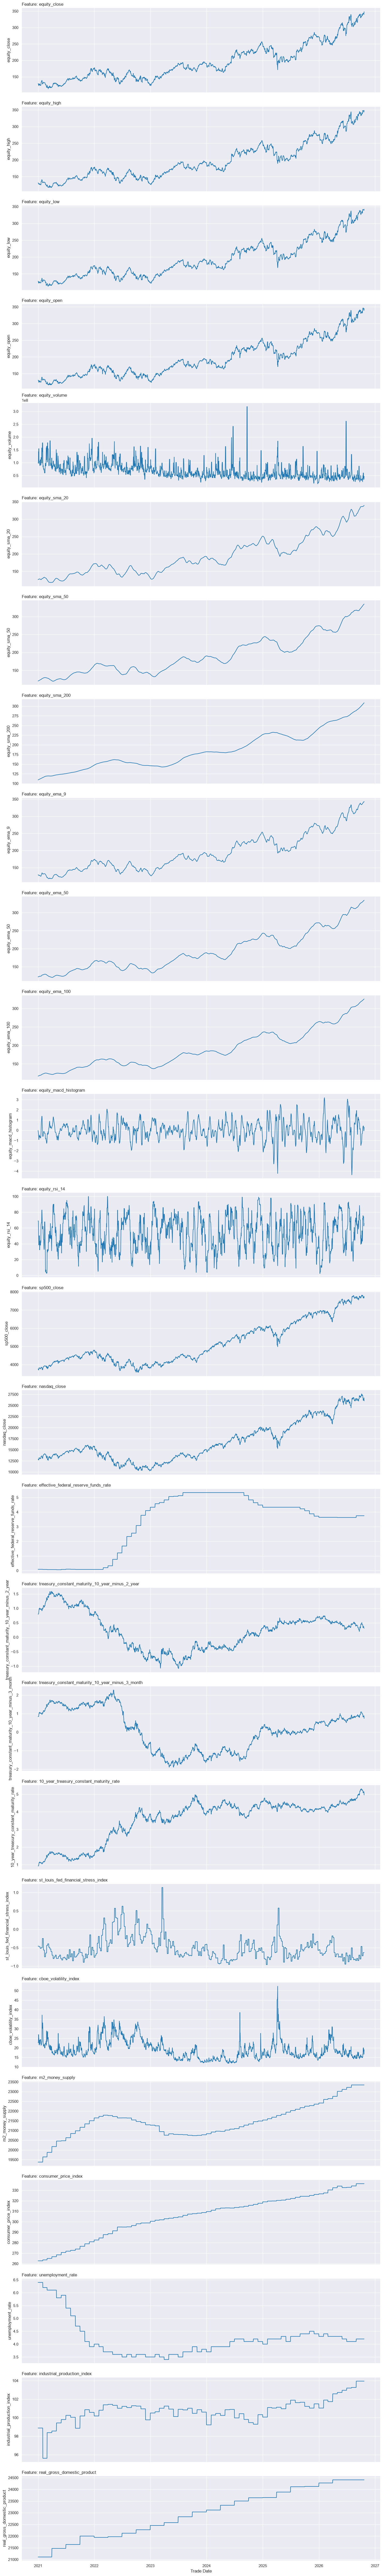

In [58]:
# Plot the time-series data for all the features in the merged dataframe using Seaborn's lineplot function
sns.set(style="darkgrid") # Set the Seaborn style to "darkgrid" for better aesthetics in the plots

# Get the list of features (columns) in the dataframe, except the target column 'equity_predicted_close'
features_list = [col for col in equity_df.columns if col != 'equity_predicted_close']

# Create a grid of subplots
fig, axes = plt.subplots(
    nrows=len(features_list), # Number of rows equal to the number of features
    ncols=1, # Number of columns is 1 since we want a single column of plots
    figsize=(15, 100), # Set the figure size to 15 inches wide and 100 inches tall to accommodate all the subplots
    sharex=True,  # Share x-axis across all time-series panels
)

# Flatten axes array in case it's multi-dimensional, loop through each feature
for i, feature in enumerate(features_list):
    ax = axes[i] # Get the current axis for the subplot
    sns.lineplot(data=equity_df, x=equity_df.index, y=feature, ax=ax, color="tab:blue") # Plot the time-series data for the current feature using Seaborn's lineplot function, with the x-axis as the index (date) and y-axis as the feature values, and set the color to blue
    ax.set_title(f"Feature: {feature}", loc="left", fontsize=12) # Set the title of the subplot to indicate the feature being plotted, aligned to the left, with a font size of 12
    ax.set_ylabel(feature) # Set the y-axis label to the feature name to indicate what is being plotted on the y-axis
    ax.set_xlabel("") # Set the x-axis label to an empty string to avoid cluttering the plots with x-axis labels for each subplot

axes[-1].set_xlabel("Trade Date") # Label the bottom x-axis
plt.tight_layout() # Adjust the layout to prevent overlapping of subplots and ensure that titles and labels are clearly visible
plt.show() # Display the plots

### Modeling

With your final dataset in hand, it is now time to build some models.  Here, you should build a number of different models with the 'equity_predicted_close' as the target. In building your models, you should explore different parameters and be sure to cross-validate your findings.

##### Linear Regression Model (Baseline)

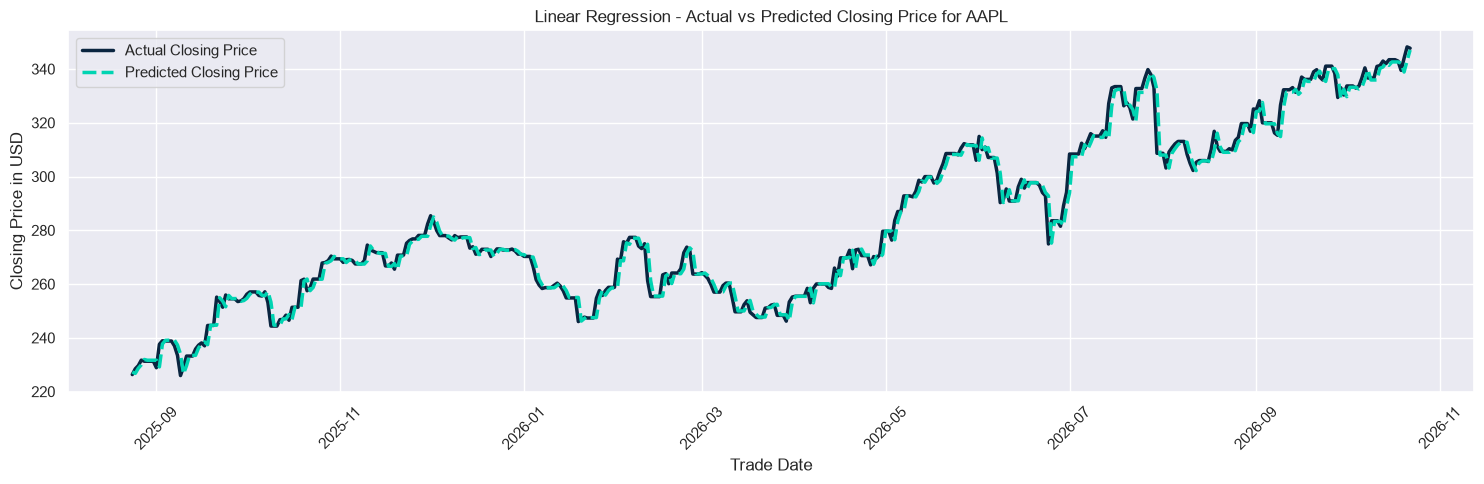

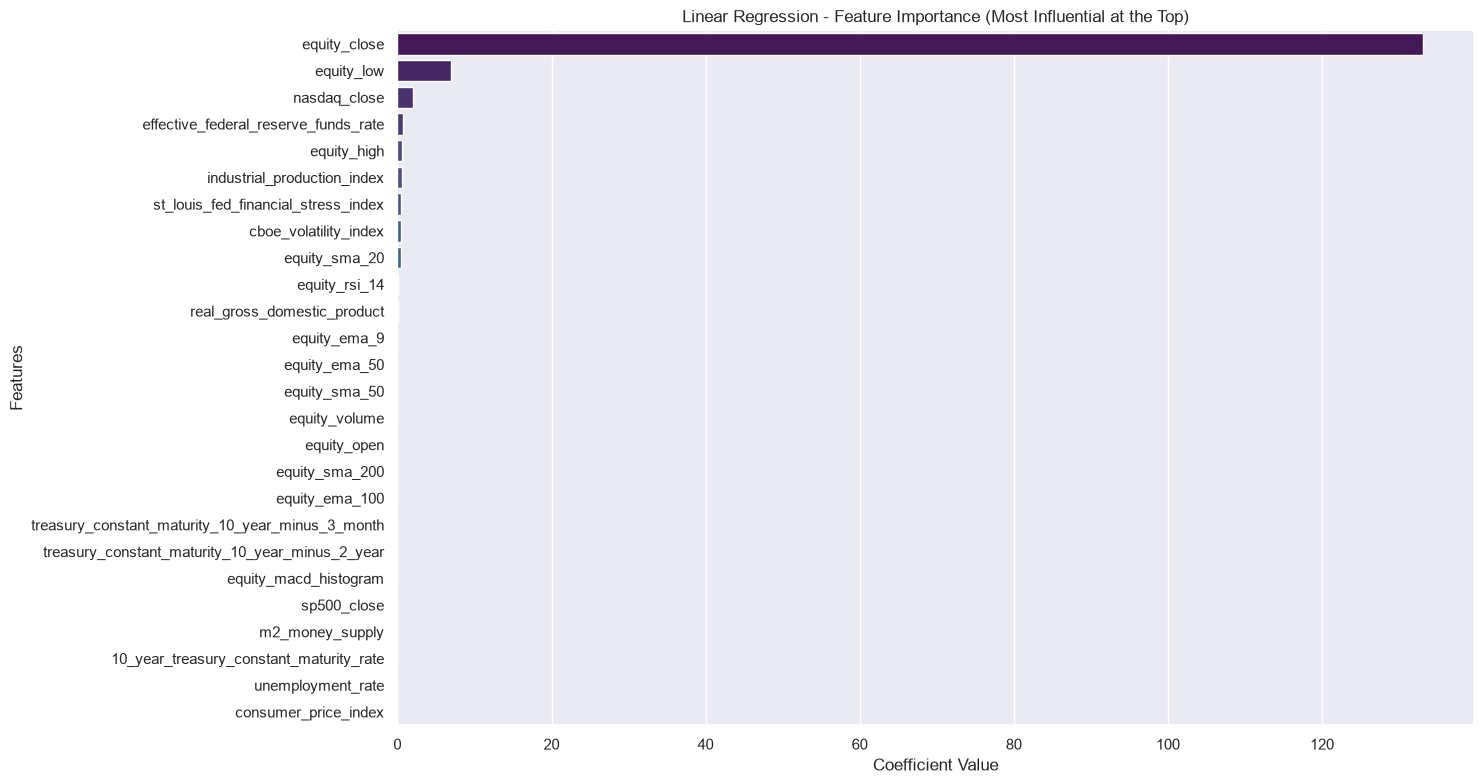

MODEL NAME:  LINEAR REGRESSION
Elapsed Time (Seconds):  11
Mean Absolute Error (MAE):  2.2386 (Best Value is Zero)
Mean Squared Error (MSE):  13.2674 (Best Value is Zero)
Root Mean Squared Error (RMSE):  3.6424 (Best Value is Zero)
R-squared (R2):  0.9863 (Best Value is One)
Last Trading Day (MM/DD/YYYY):  10/22/2026
Actual Closing Price (USD):  347.73
Predicted Closing Price (USD):  347.08


In [59]:
# Linear Regression Model

start_time = time.perf_counter() # Record start time

# Create X and y from the equity_df dataset where 'equity_predicted_close' column is the target and the remaining columns are the features
X = equity_df.drop(columns=['equity_predicted_close']) # Data Frame for Features
y = equity_df["equity_predicted_close"] # Series for Target

# Split the time series data into training and testing sets
# Since this is time series data, we will not shuffle the data and will use the first 80% of the data for training and the last 20% for testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, shuffle=False)

# Create a Pipeline with Scaling and Linear Regression
pipeline = Pipeline(steps=[
        ("scaler", MinMaxScaler()),  # Scaling is important to ensure that all features are on the same scale
        ("regressor", LinearRegression())
    ])

# Define the Parameter Grid
# The parameter grid is used to specify the hyperparameters that we want to tune for the Linear Regression model.
# In this case, we are tuning the 'fit_intercept' and 'positive' parameters of the Linear Regression model.
# fit_intercept: Whether to calculate the intercept for this model. If set to False, no intercept will be used in calculations (e.g., data is expected to be already centered).
# positive: When set to True, forces the coefficients to be positive. This can be useful when we know that the relationship between the features and the target variable is positive (e.g., as the value of a feature increases, the value of the target variable also increases).
param_grid = {"regressor__fit_intercept": [True, False],
              "regressor__positive": [True, False]}

# Time Series Split which is essential for financial data to prevent looking ahead into future data
tscv = TimeSeriesSplit(n_splits=5)

# Create a Grid Search with Cross-Validation
# Cross-Validation is used to avoid data leakage and overfitting. The number of splits is set to 5, which means that the dataset will be split into 5 folds
# Scoring is set to "neg_mean_squared_error" since we are predicting a continuous variable (equity closing price)
# n_jobs=-1 means that all available CPU cores will be used for parallel processing, which can speed up the grid search process.
grid_search = GridSearchCV(estimator=pipeline, param_grid=param_grid, cv=tscv, scoring="neg_mean_squared_error", n_jobs=-1)

# Fit the Grid Search to the training data
grid_search.fit(X_train, y_train)

# Predict using the Best Model
best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)

# Evaluate Metrics
mae = round(mean_absolute_error(y_test, y_pred),4) # Best Value is 0. Measures the average absolute distance between actual and predicted values. It treats all errors equally.
mse = round(mean_squared_error(y_test, y_pred),4) # Best Value is 0. Measures the average squared distance between actual and predicted values. It penalizes larger errors more than smaller errors.
rmse = round(np.sqrt(mse),4) # Best Value is 0. Measures the square root of the average squared distance between actual and predicted values. It is in the same unit as the target variable and is more interpretable than MSE.
r2 = round(r2_score(y_test, y_pred),4) # Best Value is 1. Measures the proportion of variance in the target variable that is explained by the model. It ranges from 0 to 1, with higher values indicating better model performance.

# Plot the Actual vs Predicted Closing Price for the Test Set
# Create DatetimeIndex object to store the index of the test set
test_data_DatetimeIndex = X_test.index

# Create a DataFrame in Wide Format for Seaborn Line Plot
df_wide = pd.DataFrame({'Actual Closing Price': y_test, 'Predicted Closing Price': y_pred}, index=test_data_DatetimeIndex)

# Define a custom color palette for the line plot to make it visually appealing and easy to distinguish between actual and predicted values
custom_palette = {
    'Actual Closing Price': '#0A2540',    # Deep Navy Blue
    'Predicted Closing Price': '#00D4B2'  # Bright Teal
}

plt.figure(figsize=(15, 5)) # Set the figure size to 15 inches wide and 5 inches tall
sns.lineplot(data=df_wide, palette=custom_palette, linewidth=2.5) # Plot the actual and predicted closing prices using Seaborn's lineplot function, with the specified color palette and line width
plt.title(f'Linear Regression - Actual vs Predicted Closing Price for {ticker}') # Set the title of the plot to include the ticker symbol for clarity
plt.xlabel('Trade Date') # Set the x-axis label to 'Trade Date' to indicate that the x-axis represents the dates of the trades
plt.ylabel('Closing Price in USD') # Set the y-axis label to 'Closing Price' to indicate that the y-axis represents the closing prices of the equity
plt.xticks(rotation=45) # Rotate the x-axis labels by 45 degrees for better readability, especially when there are many dates on the x-axis
plt.tight_layout() # Adjust the padding of the plot to ensure that all elements are visible and not cut off
plt.show() # Display the plot

# Plot the most influential features in the top using Seaborn
# Create dataframe for Features and Coefficients
feature_coefficient_df = pd.DataFrame({
    'Feature': [name.split('__')[-1] for name in list(best_model.named_steps['scaler'].get_feature_names_out())],
    'Coefficient': best_model.named_steps['regressor'].coef_
})

plt.figure(figsize=(15, 8)) # Set the figure size to 15 inches wide and 8 inches tall
sns.barplot(data=feature_coefficient_df.sort_values(by='Coefficient', ascending=False), x='Coefficient', y='Feature', palette='viridis') # Plot the coefficients of the features using Seaborn's barplot function, sorting the features by their coefficient values in descending order, and using the 'viridis' color palette for better visual distinction
plt.title(f'Linear Regression - Feature Importance (Most Influential at the Top)') # Set the title of the plot to indicate that it shows the features most influencing the equity closing price for the specified ticker
plt.xlabel('Coefficient Value') # Set the x-axis label to 'Coefficient Value' to indicate that the x-axis represents the values of the coefficients for each feature
plt.ylabel('Features') # Set the y-axis label to 'Feature Name' to indicate that the y-axis represents the names of the features used in the model
plt.tight_layout() # Adjust the padding of the plot to ensure that all elements are visible and not cut off
plt.show() # Display the plot

end_time = time.perf_counter() # Record end time
elapsed_seconds = round(end_time - start_time, 0) # Calculate elapsed time in Seconds

# Create Summary Statistics
lr_metrics_dict = {"Model Name" : "LINEAR REGRESSION",
                   "Elapsed Time (Seconds)" : int(elapsed_seconds),
                   "Mean Absolute Error (MAE)" : mae,
                   "Mean Squared Error (MSE)" : mse,
                   "Root Mean Squared Error (RMSE)" : rmse.item(),
                   "R-squared (R2)" : r2,
                   "Last Trading Day (MM/DD/YYYY)": test_data_DatetimeIndex[-1].strftime("%m/%d/%Y"),
                   "Actual Closing Price (USD)" : round(y_test.iloc[-1],2).item(),
                   "Predicted Closing Price (USD)" : round(y_pred[-1],2).item()
                   }

print("MODEL NAME: ", lr_metrics_dict["Model Name"])
print("Elapsed Time (Seconds): ", lr_metrics_dict["Elapsed Time (Seconds)"])
print("Mean Absolute Error (MAE): ", lr_metrics_dict["Mean Absolute Error (MAE)"], "(Best Value is Zero)")
print("Mean Squared Error (MSE): ", lr_metrics_dict["Mean Squared Error (MSE)"], "(Best Value is Zero)")
print("Root Mean Squared Error (RMSE): ", lr_metrics_dict["Root Mean Squared Error (RMSE)"], "(Best Value is Zero)")
print("R-squared (R2): ", lr_metrics_dict["R-squared (R2)"], "(Best Value is One)")
print("Last Trading Day (MM/DD/YYYY): ", lr_metrics_dict["Last Trading Day (MM/DD/YYYY)"])
print("Actual Closing Price (USD): ", lr_metrics_dict["Actual Closing Price (USD)"])
print("Predicted Closing Price (USD): ", lr_metrics_dict["Predicted Closing Price (USD)"])

##### SARIMAX Model

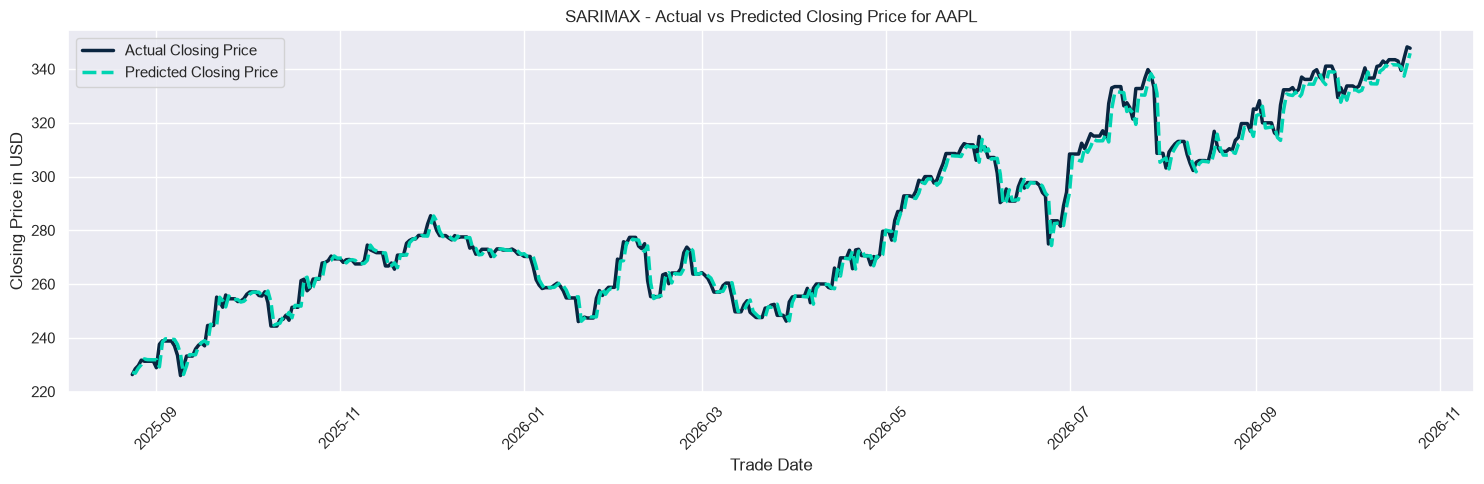

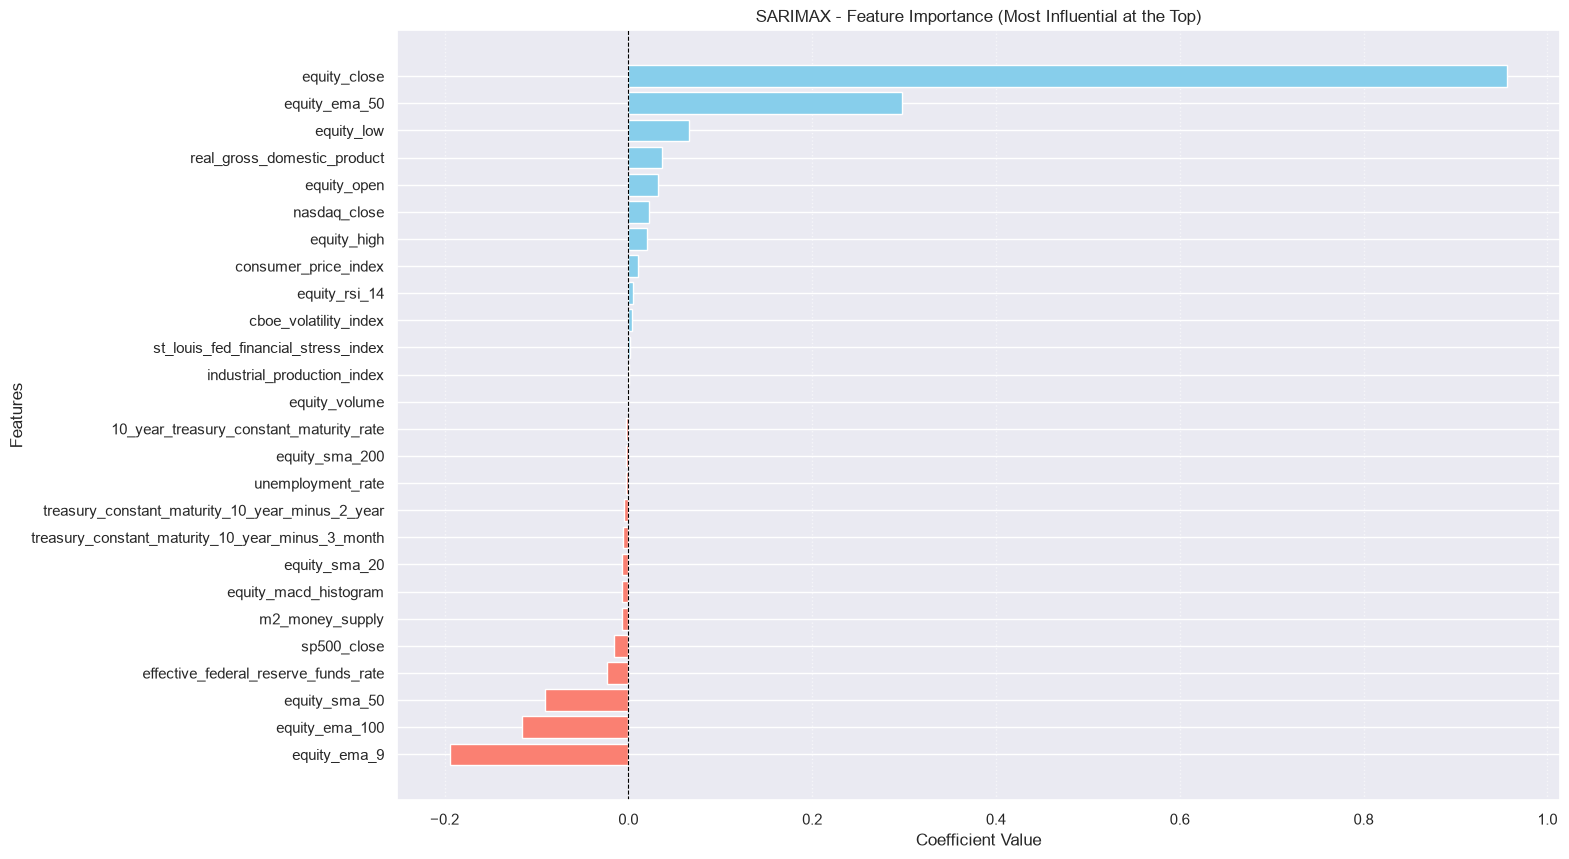

MODEL NAME:  SARIMAX
Elapsed Time (Seconds):  125
Mean Absolute Error (MAE):  2.43 (Best Value is Zero)
Mean Squared Error (MSE):  14.2805 (Best Value is Zero)
Root Mean Squared Error (RMSE):  3.779 (Best Value is Zero)
R-squared (R2):  0.9852 (Best Value is One)
Last Trading Day (MM/DD/YYYY):  10/22/2026
Actual Closing Price (USD):  347.73
Predicted Closing Price (USD):  345.87


In [60]:
# SARIMAX Model

start_time = time.perf_counter() # Record start time

# Create X and y from the equity_df dataset where 'equity_predicted_close' column is the target and the remaining columns are the features
X = equity_df.drop(columns=['equity_predicted_close']) # Data Frame for Features
y = equity_df["equity_predicted_close"] # Series for Target

# Split the time series data into training and testing sets
# Since this is time series data, we will not shuffle the data and will use the first 80% of the data for training and the last 20% for testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, shuffle=False)

# Scaling the dataset (Separately to avoid leakage)
scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled = scaler_X.transform(X_test)

y_train_scaled = scaler_y.fit_transform(y_train.values.reshape(-1, 1))
y_test_scaled = scaler_y.transform(y_test.values.reshape(-1, 1))

# Tune Hyperparameters
auto_model = pm.auto_arima (
    y = y_train_scaled,       # Target variable which has been scaled/normalized to help the model algorithm converge faster
    X = X_train_scaled,       # Exogenous variables which has been scaled/normalized
    start_p = 1,              # Limits the search for the core non-seasonal parts of the model. It searches for the best Autoregressive (p) terms between start_p and max_p
    max_p = 3,
    start_q = 1,              # Limits the search for the core non-seasonal parts of the model. It searches for the best Moving Average (q) terms between start_q and max_q
    max_q = 3,
    d = None,                 # Let auto_arima find optimal differencing 'd' for non-seasonal differences needed to make your target data stationary (removing trends)
    seasonal = True,          # Tells the model to look for a seasonal pattern. Setting m=5 specifies a weekly cycle based on 5 days
    m = 5,
    start_P = 0,              # Limits the search for the seasonal Autoregressive component up to 2 lags specified by max_P
    max_P = 2,
    trace = False,            # Cleanup parameter - Run the code completely silently in the background
    error_action = "ignore",  # Cleanup parameter - Ignore optimization errors
    suppress_warnings = True, # Cleanup parameter - Hide long lists of text readouts
)

# Train the Model
final_model = SARIMAX (
    endog = y_train_scaled,       # Target variable which has been scaled/normalized to help the model algorithm converge faster
    exog = X_train_scaled,        # Exogenous variables which has been scaled/normalized
    order = auto_model.order,     # Optimal (p, d, q) non-seasonal hyperparameters. p is Autoregressive order (past values), d is Differencing order (to make the data stationary), q is Moving average order (past forecast errors)
    seasonal_order = auto_model.seasonal_order, # Optimal (P, D, Q, s) seasonal hyperparameters
).fit(disp = False)               # Suppresses all convergence output and logs during the fit

# Forecast requires the scaled test exogenous features
y_pred_scaled = final_model.forecast (
    steps = len(X_test),   # The number of out-of-sample time steps to forecast
    exog = X_test_scaled   # Future values of the exogenous regressors corresponding only to the forecasted time steps
)

# Bring back original values
# Reshape to 2D array for inverse_transform
y_pred_scaled_2d = y_pred_scaled.reshape(-1, 1)

# Inverse transform to bring back original dollar scale
y_pred_original = scaler_y.inverse_transform(y_pred_scaled_2d)
y_test_original = scaler_y.inverse_transform(y_test_scaled)

# Convert to clean 1D arrays or series
y_pred_original = y_pred_original.flatten()
y_test_original = y_test_original.flatten()

# Evaluate Metrics
mae = round(mean_absolute_error(y_test_original, y_pred_original),4) # Best Value is 0. Measures the average absolute distance between actual and predicted values. It treats all errors equally.
mse = round(mean_squared_error(y_test_original, y_pred_original),4) # Best Value is 0. Measures the average squared distance between actual and predicted values. It penalizes larger errors more than smaller errors.
rmse = round(np.sqrt(mse),4) # Best Value is 0. Measures the square root of the average squared distance between actual and predicted values. It is in the same unit as the target variable and is more interpretable than MSE.
r2 = round(r2_score(y_test_original, y_pred_original),4) # Best Value is 1. Measures the proportion of variance in the target variable that is explained by the model. It ranges from 0 to 1, with higher values indicating better model performance.

# Plot the Actual vs Predicted Closing Price for the Test Set
# Create DatetimeIndex object to store the index of the test set
test_data_DatetimeIndex = X_test.index

# Create a DataFrame in Wide Format for Seaborn Line Plot
df_wide = pd.DataFrame({'Actual Closing Price': y_test_original, 'Predicted Closing Price': y_pred_original}, index=test_data_DatetimeIndex)

# Define a custom color palette for the line plot to make it visually appealing and easy to distinguish between actual and predicted values
custom_palette = {
    'Actual Closing Price': '#0A2540',    # Deep Navy Blue
    'Predicted Closing Price': '#00D4B2'  # Bright Teal
}

plt.figure(figsize=(15, 5)) # Set the figure size to 15 inches wide and 5 inches tall
sns.lineplot(data=df_wide, palette=custom_palette, linewidth=2.5) # Plot the actual and predicted closing prices using Seaborn's lineplot function, with the specified color palette and line width
plt.title(f'SARIMAX - Actual vs Predicted Closing Price for {ticker}') # Set the title of the plot to include the ticker symbol for clarity
plt.xlabel('Trade Date') # Set the x-axis label to 'Trade Date' to indicate that the x-axis represents the dates of the trades
plt.ylabel('Closing Price in USD') # Set the y-axis label to 'Closing Price' to indicate that the y-axis represents the closing prices of the equity
plt.xticks(rotation=45) # Rotate the x-axis labels by 45 degrees for better readability, especially when there are many dates on the x-axis
plt.tight_layout() # Adjust the padding of the plot to ensure that all elements are visible and not cut off
plt.show() # Display the plot

# Plot the most influential features in the top
features_list = X.columns.to_list()
# Exogenous feature parameters in statsmodels are prefixed with 'x' (e.g., x1, x2, x3...)
# Filter for these specific coefficients and map them back to your features_list
exog_params = [final_model.params[i] for i in range(len(features_list))]

feature_importance = pd.DataFrame(
    {
        "Feature": features_list,
        "Coefficient": exog_params
    }
)

# Sort features by their impact
feature_importance = feature_importance.sort_values(by="Coefficient", ascending=False)

plt.figure(figsize=(15, 10))
colors = ["salmon" if c < 0 else "skyblue" for c in feature_importance["Coefficient"]]

plt.barh(
    feature_importance["Feature"],
    feature_importance["Coefficient"],
    color=colors,
)
plt.axvline(0, color="black", linestyle="--", linewidth=0.8)
plt.xlabel("Coefficient Value")
plt.ylabel("Features")
plt.title("SARIMAX - Feature Importance (Most Influential at the Top)")
plt.gca().invert_yaxis()
plt.grid(axis="x", linestyle=":", alpha=0.6)
plt.show()

end_time = time.perf_counter() # Record end time
elapsed_seconds = round(end_time - start_time, 0) # Calculate elapsed time in Seconds

# Create Summary Statistics
sarimax_metrics_dict = {"Model Name" : "SARIMAX",
                        "Elapsed Time (Seconds)" : int(elapsed_seconds),
                        "Mean Absolute Error (MAE)" : mae,
                        "Mean Squared Error (MSE)" : mse,
                        "Root Mean Squared Error (RMSE)" : rmse.item(),
                        "R-squared (R2)" : r2,
                        "Last Trading Day (MM/DD/YYYY)": test_data_DatetimeIndex[-1].strftime("%m/%d/%Y"),
                        "Actual Closing Price (USD)" : round(y_test_original[-1],2).item(),
                        "Predicted Closing Price (USD)" : round(y_pred_original[-1],2).item()
                        }

print("MODEL NAME: ", sarimax_metrics_dict["Model Name"])
print("Elapsed Time (Seconds): ", sarimax_metrics_dict["Elapsed Time (Seconds)"])
print("Mean Absolute Error (MAE): ", sarimax_metrics_dict["Mean Absolute Error (MAE)"], "(Best Value is Zero)")
print("Mean Squared Error (MSE): ", sarimax_metrics_dict["Mean Squared Error (MSE)"], "(Best Value is Zero)")
print("Root Mean Squared Error (RMSE): ", sarimax_metrics_dict["Root Mean Squared Error (RMSE)"], "(Best Value is Zero)")
print("R-squared (R2): ", sarimax_metrics_dict["R-squared (R2)"], "(Best Value is One)")
print("Last Trading Day (MM/DD/YYYY): ", sarimax_metrics_dict["Last Trading Day (MM/DD/YYYY)"])
print("Actual Closing Price (USD): ", sarimax_metrics_dict["Actual Closing Price (USD)"])
print("Predicted Closing Price (USD): ", sarimax_metrics_dict["Predicted Closing Price (USD)"])

##### LSTM Model

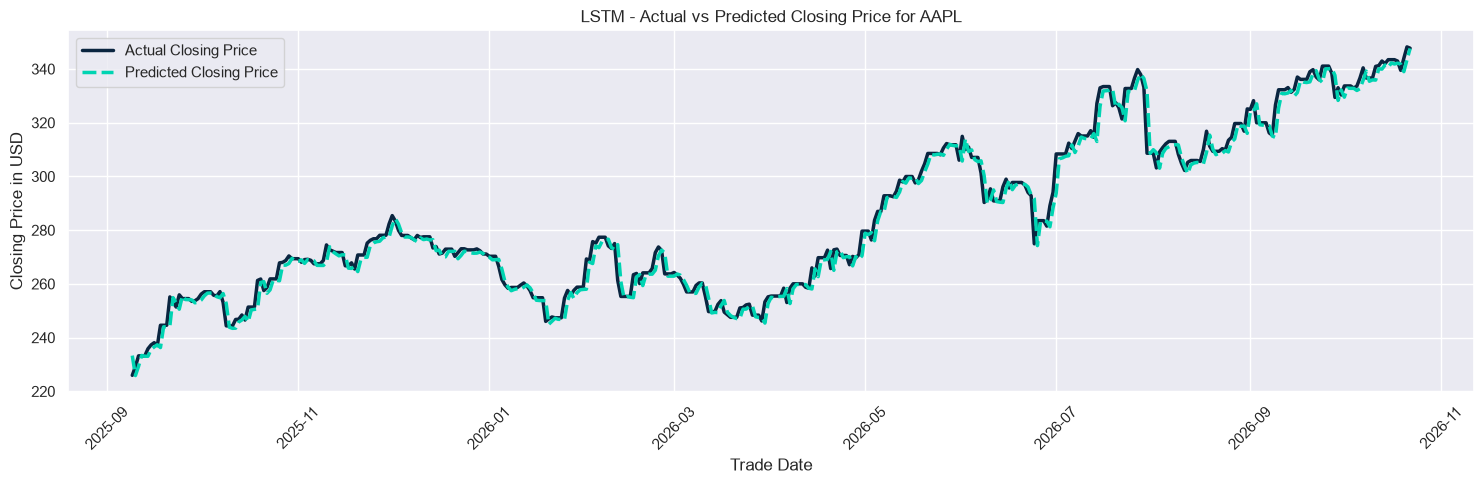

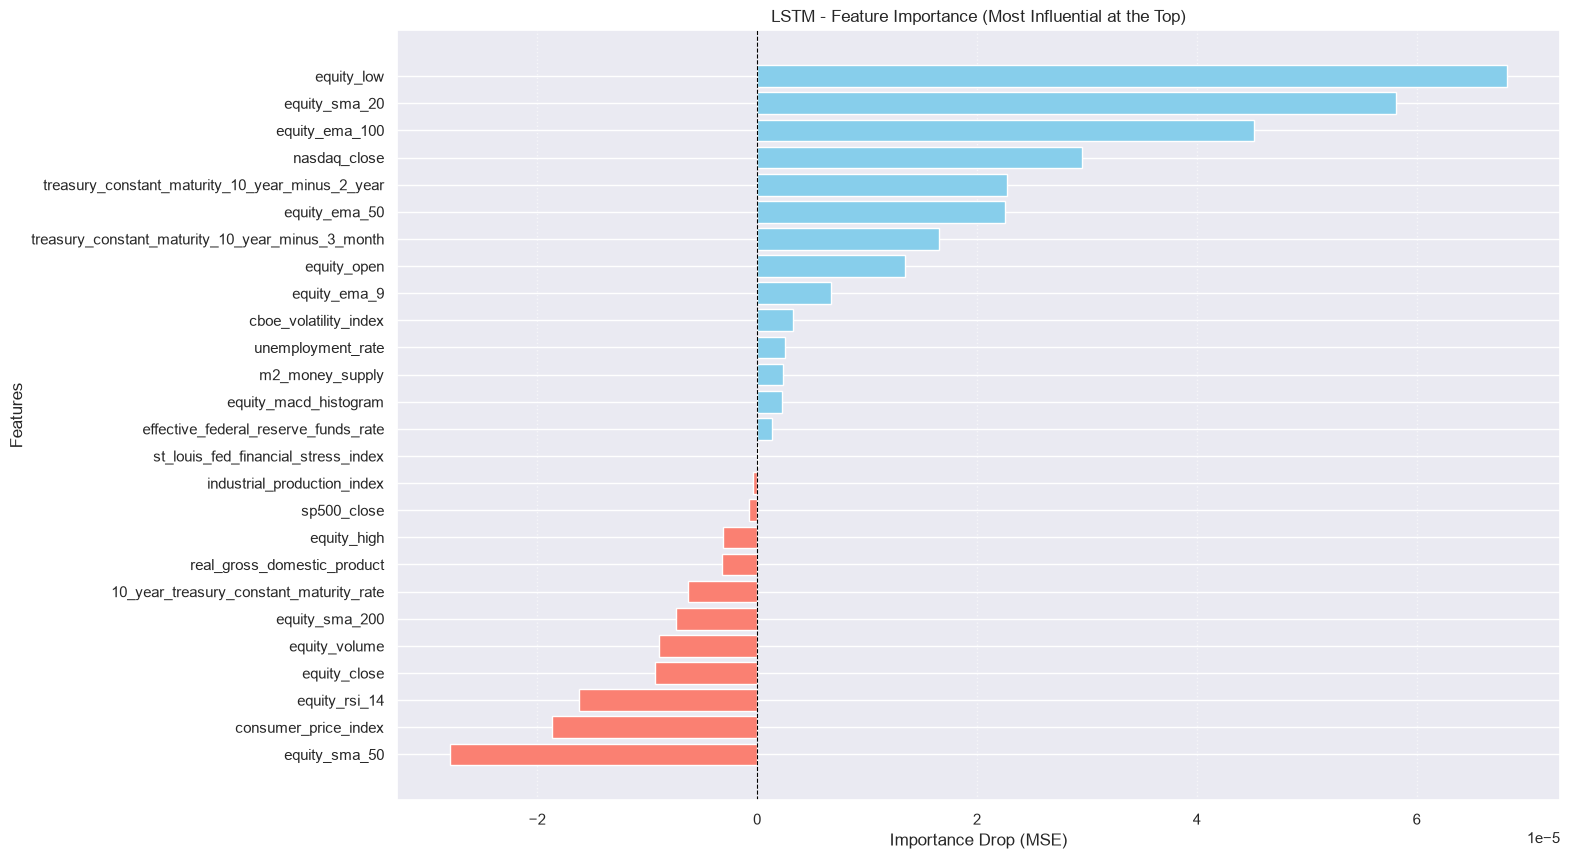

MODEL NAME:  LSTM
Elapsed Time (Seconds):  169
Mean Absolute Error (MAE):  2.4882 (Best Value is Zero)
Mean Squared Error (MSE):  14.2631 (Best Value is Zero)
Root Mean Squared Error (RMSE):  3.7767 (Best Value is Zero)
R-squared (R2):  0.9843 (Best Value is One)
Last Trading Day (MM/DD/YYYY):  10/22/2026
Actual Closing Price (USD):  347.73
Predicted Closing Price (USD):  347.65


In [61]:
# LSTM Model

start_time = time.perf_counter() # Record start time

# Create Time-Series Sequences (Lookback window) to transform a time series into input (X) and target (y) pairs
# Input Parameters:
#  data: Time-series data
#  lookback: Number of time steps to use as input
#  target_idx: Index Position of the Target variable in the dataframe
# Returns:
#  X: Array of shape (num_samples, lookback)
#  y: Array of shape (num_samples,) predicting the next value
def create_sequences(data, lookback, target_idx):
    X, y = [], []
    for i in range(len(data) - lookback):
        X.append(data[i:(i + lookback), :])
        y.append(data[i + lookback, target_idx])
    return np.array(X), np.array(y)

# Define Hypermodel for Bayesian Optimization
# Input Parameters:
#  hp: Special object passed by the tuning algorithm for HyperParameters
# Returns:
#  model: A fully configured and compiled Keras Model instance
def build_model(hp):
    model = Sequential() # Initialize the empty linear container
    
    # Add LSTM Input first layer to process the sequence data
    model.add(LSTM(
        units = hp.Int('units_1', min_value=32, max_value=128, step=32), # Tunes the number of units (neurons) inside the LSTM layer from 32 to 128 increment of 32
        return_sequences = hp.Choice('return_seq', [True, False]), # Try both True/False during training to see which one yields better validation accuracy
        input_shape = (X_train.shape[1], X_train.shape[2])  # Parameters are Training dataset Number of Rows and Number of Columns respectively
    ))
    
    # 'return_seq'=True: Outputs a 3D tensor (batch_size, timesteps, output_features), Required by the next LSTM layer
    # 'return_seq'=False: Outputs a 2D tensor (batch_size, output_features), Required by Dense layers, causes an error if sent to another LSTM
    if hp.get('return_seq'):
        # Add LSTM second layer to process the sequence data
        model.add(LSTM(units = hp.Int('units_2', min_value=16, max_value=64, step=16), # Tunes the number of units (neurons) inside the LSTM layer from 16 to 64 increment of 16
                       return_sequences = False # Outputs a 2D tensor
                       ))
        
    # Add Dropout Layer to randomly "turn off" a percentage of neurons during training to avoid overfitting
    model.add(Dropout(rate = hp.Float('dropout', min_value=0.1, max_value=0.4, step=0.1))) # Lowest dropout rate the tuner will try is 10% of neurons to be dropped, Highest 40%, Increment of 10%

    # Add Output Dense Layer to return the Predicted Closing Price
    model.add(Dense(1)) # 1 Neuron
    
    # It configures the learning process by defining how the model should update its weights and how it should measure its performance
    # Adam is the optimization algorithm used to update the model's weights during training to minimize errors
    # Min/Max Value defines the boundaries for the search. The tuner will experiment with values inside this range
    # 'log' tells the tuner to explore the range on a logarithmic scale
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate = hp.Float('lr', min_value=0.0001, max_value=0.01, sampling='log')),
        loss='mse' # Loss function for Regression Model - Mean Squared Error
    )
    return model

# Fix Naive Trap: Transform entire dataset to Percentage Returns (Stationary)
# This removes both linear trend and scaling disparities across features
df_returns = equity_df.pct_change()
df_returns = df_returns.iloc[1:] # Drop the First row which is a NULL row after Percentage Change
df_returns.fillna(0, inplace=True) # Replace NaN by Zero
df_returns.replace([np.inf, -np.inf], 0, inplace=True) # Replace +/- Infinity by Zero

# Train/Test Split (Chronological split to preserve temporal patterns)
train_size = int(len(df_returns) * 0.8)
train_df = df_returns.iloc[:train_size]
test_df = df_returns.iloc[train_size:]

# Extract the matching datetime index for test_df
test_index_df = df_returns.index[train_size:]

# Scale the Features (Fit ONLY on training data to prevent leakage)
scaler = MinMaxScaler(feature_range=(-1, 1)) # -1 to 1 works better for returns centering around 0
train_scaled = scaler.fit_transform(train_df)
test_scaled = scaler.transform(test_df)

# Separate scaler for the target returns column to make inverse-transform seamless
target_scaler = MinMaxScaler(feature_range=(-1, 1))
target_scaler.fit(train_df[['equity_predicted_close']])

# Create Time-Series Sequences (Lookback window) to transform a time series into input (X) and target (y) pairs
LOOKBACK = 15 # Number of time steps to use as input
X_train, y_train = create_sequences(train_scaled, LOOKBACK, equity_df.columns.get_loc('equity_predicted_close'))
X_test, y_test = create_sequences(test_scaled, LOOKBACK, equity_df.columns.get_loc('equity_predicted_close'))

# Execute Bayesian Optimization (Faster than Random/Grid Search) with Early Stopping
tuner = kt.BayesianOptimization(
    hypermodel = build_model, # This is a user-defined function passed into the tuner. It contains the blueprint of your LSTM model and specifies which hyperparameters are allowed to change
    objective = 'val_loss', # This tells the tuner how to judge success. It will try to minimize the validation loss
    max_trials = 5, # The tuner will build, train, and evaluate exactly 5 different model configurations before stopping and picking the winner
    directory = 'temp', # temp directory where tuned model is stored
    project_name = 'lstm_tuned_model', # project name for the tuned model
    overwrite = True # Created the tuned model every time
)

# It is a regularization technique used in deep learning to prevent a neural network from overfitting and to save training time
# It tells to watch the validation loss for 7 epochs to wait for an improvement before stopping
# restore_best_weights=True means automatically rolls back the model's weights to the exact epoch where the validation loss was at its lowest
early_stopping = EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True, verbose=0)

# Execute hyperparameter tuning search
tuner.search(
    X_train, # Training Data for Input Features
    y_train, # Training Data for Target
    epochs = 50, # Maximum number of times each model trial will see the entire training dataset
    batch_size = 32, # Number of training samples the model processes at once before updating its internal weights
    validation_split = 0.1, # Tells the tuner to automatically set aside 10% of your training data to use as validation data
    callbacks = [early_stopping], # Ensures that if a specific model trial stops improving on the validation data, it cuts the training short instead of wasting time running all 50 epochs
    verbose = 0 # Hide the Output Messages
)

# It retrieves the single top-performing model found during a KerasTuner hyperparameter search
best_model = tuner.get_best_models(num_models=1)[0]

# Predict in Scaled value
pred_scaled = best_model.predict(X_test, verbose=0)

# Inverse transform predictions and actuals back into raw Return values
pred_returns = target_scaler.inverse_transform(pred_scaled).flatten()
actual_returns = target_scaler.inverse_transform(y_test.reshape(-1, 1)).flatten()

# Calculate the exact chronological alignment index in the original dataframe
# Account for offsets: 1 (pct_change) + LOOKBACK (sequencing)
alignment_offset = 1 + LOOKBACK 
test_start_idx = train_size + alignment_offset

# Extract actual target prices for the test window duration
actual_prices = equity_df.loc[equity_df.index[test_start_idx : test_start_idx + len(actual_returns)], 'equity_predicted_close'].values

# Extract the true preceding prices (t-1) for every step in the test window
previous_true_prices = equity_df.loc[equity_df.index[test_start_idx - 1 : test_start_idx + len(actual_returns) - 1], 'equity_predicted_close'].values

# Reconstruct predictions: True Previous Price * (1 + Predicted Return)
# This removes cumulative drift or mirror inversion caused by feedback loops
pred_prices = previous_true_prices * (1 + pred_returns)

# Evaluate Metrics
mae = round(mean_absolute_error(actual_prices, pred_prices),4) # Best Value is 0. Measures the average absolute distance between actual and predicted values. It treats all errors equally.
mse = round(mean_squared_error(actual_prices, pred_prices),4) # Best Value is 0. Measures the average squared distance between actual and predicted values. It penalizes larger errors more than smaller errors.
rmse = round(np.sqrt(mse),4) # Best Value is 0. Measures the square root of the average squared distance between actual and predicted values. It is in the same unit as the target variable and is more interpretable than MSE.
r2 = round(r2_score(actual_prices, pred_prices),4) # Best Value is 1. Measures the proportion of variance in the target variable that is explained by the model. It ranges from 0 to 1, with higher values indicating better model performance.

# Plot the Actual vs Predicted Closing Price for the Test Set
feature_names = equity_df.columns.tolist() # List of all Feature Names
# Create DatetimeIndex object to store the index of the test set
test_data_DatetimeIndex = test_index_df[-1 * len(actual_prices) :]

# Create a DataFrame in Wide Format for Seaborn Line Plot
df_wide = pd.DataFrame({'Actual Closing Price': actual_prices, 'Predicted Closing Price': pred_prices}, index=test_data_DatetimeIndex)

# Define a custom color palette for the line plot to make it visually appealing and easy to distinguish between actual and predicted values
custom_palette = {
    'Actual Closing Price': '#0A2540',    # Deep Navy Blue
    'Predicted Closing Price': '#00D4B2'  # Bright Teal
}

plt.figure(figsize=(15, 5)) # Set the figure size to 15 inches wide and 5 inches tall
sns.lineplot(data=df_wide, palette=custom_palette, linewidth=2.5) # Plot the actual and predicted closing prices using Seaborn's lineplot function, with the specified color palette and line width
plt.title(f'LSTM - Actual vs Predicted Closing Price for {ticker}') # Set the title of the plot to include the ticker symbol for clarity
plt.xlabel('Trade Date') # Set the x-axis label to 'Trade Date' to indicate that the x-axis represents the dates of the trades
plt.ylabel('Closing Price in USD') # Set the y-axis label to 'Closing Price' to indicate that the y-axis represents the closing prices of the equity
plt.xticks(rotation=45) # Rotate the x-axis labels by 45 degrees for better readability, especially when there are many dates on the x-axis
plt.tight_layout() # Adjust the padding of the plot to ensure that all elements are visible and not cut off
plt.show() # Display the plot

# Plot the most influential features in the top
rng = np.random.default_rng(seed=42) # Initialize the Generator with a specific seed
baseline_preds = best_model.predict(X_test, verbose=0) # Predict in Scaled value for Baseline Prediction
baseline_mse = mean_squared_error(y_test, baseline_preds) # Calculate MSE for Baseline Prediction

feature_importance = {}
# Loop through all Input feature indices to evaluate performance drops
for f_idx in range(X_test.shape[2]-1):
    X_test_permuted = X_test.copy()
    
    # Shuffle this specific feature across all samples and lookback timesteps
    for seq in range(X_test.shape[0]):
        rng.shuffle(X_test_permuted[seq, :, f_idx])
        
    permuted_preds = best_model.predict(X_test_permuted, verbose=0) # Predict in Scaled value after the Shuffle for each feature
    permuted_mse = mean_squared_error(y_test, permuted_preds) # Calculate MSE after the Shuffle for each feature
    
    # Importance score = how much worse the error got when this feature was ruined
    feature_importance[feature_names[f_idx]] = permuted_mse - baseline_mse # If the difference is high, that feature is important

# Sort features strictly from Most Influential to Least Influential
sorted_importance = sorted(feature_importance.items(), key=lambda x: x[1], reverse=False) # False for horizontal plot alignment
feature_important_df = pd.DataFrame(sorted_importance, columns=['Feature', 'Importance Drop (MSE)'])

# Plot Most Influential Features (Top to Least)
plt.figure(figsize=(15, 10))
# Color code by direction of impact (positive = green, negative = red)
colors = ["salmon" if c < 0 else "skyblue" for c in feature_important_df['Importance Drop (MSE)']]

plt.barh(
    feature_important_df['Feature'],
    feature_important_df['Importance Drop (MSE)'],
    color=colors,
)
plt.axvline(0, color="black", linestyle="--", linewidth=0.8)
plt.xlabel("Importance Drop (MSE)")
plt.ylabel("Features")
plt.title("LSTM - Feature Importance (Most Influential at the Top)")
plt.grid(axis="x", linestyle=":", alpha=0.6)
plt.show()

end_time = time.perf_counter() # Record end time
elapsed_seconds = round(end_time - start_time, 0) # Calculate elapsed time in Seconds

# Create Summary Statistics
lstm_metrics_dict = {"Model Name" : "LSTM",
                     "Elapsed Time (Seconds)" : int(elapsed_seconds),
                     "Mean Absolute Error (MAE)" : mae,
                     "Mean Squared Error (MSE)" : mse,
                     "Root Mean Squared Error (RMSE)" : rmse.item(),
                     "R-squared (R2)" : r2,
                     "Last Trading Day (MM/DD/YYYY)": test_data_DatetimeIndex[-1].strftime("%m/%d/%Y"),
                     "Actual Closing Price (USD)" : round(actual_prices[-1],2).item(),
                     "Predicted Closing Price (USD)" : round(pred_prices[-1],2).item()
                     }

print("MODEL NAME: ", lstm_metrics_dict["Model Name"])
print("Elapsed Time (Seconds): ", lstm_metrics_dict["Elapsed Time (Seconds)"])
print("Mean Absolute Error (MAE): ", lstm_metrics_dict["Mean Absolute Error (MAE)"], "(Best Value is Zero)")
print("Mean Squared Error (MSE): ", lstm_metrics_dict["Mean Squared Error (MSE)"], "(Best Value is Zero)")
print("Root Mean Squared Error (RMSE): ", lstm_metrics_dict["Root Mean Squared Error (RMSE)"], "(Best Value is Zero)")
print("R-squared (R2): ", lstm_metrics_dict["R-squared (R2)"], "(Best Value is One)")
print("Last Trading Day (MM/DD/YYYY): ", lstm_metrics_dict["Last Trading Day (MM/DD/YYYY)"])
print("Actual Closing Price (USD): ", lstm_metrics_dict["Actual Closing Price (USD)"])
print("Predicted Closing Price (USD): ", lstm_metrics_dict["Predicted Closing Price (USD)"])

### Evaluation

With some modeling accomplished, we aim to reflect on what we identify as a high-quality model and what we are able to learn from this.  We should review our business objective and explore how well we can provide meaningful insight to the client. Your goal now is to distill your findings and determine whether the earlier phases need revisitation and adjustment or if you have information of value to bring back to your client.

##### Display Summary Statistics for all the Models

In [62]:
# Display Summary Statistics for all the Models
print(f"{'MODEL NAME':<45}", f"{lr_metrics_dict['Model Name']:>20}", f"{sarimax_metrics_dict['Model Name']:>20}", f"{lstm_metrics_dict['Model Name']:>20}")
print(f"{'Elapsed Time (Seconds)':<45}", f"{lr_metrics_dict['Elapsed Time (Seconds)']:>20}", f"{sarimax_metrics_dict['Elapsed Time (Seconds)']:>20}", f"{lstm_metrics_dict['Elapsed Time (Seconds)']:>20}")
print(f"{'Mean Absolute Error (MAE) (Best is 0)':<45}", f"{lr_metrics_dict['Mean Absolute Error (MAE)']:>20}", f"{sarimax_metrics_dict['Mean Absolute Error (MAE)']:>20}", f"{lstm_metrics_dict['Mean Absolute Error (MAE)']:>20}")
print(f"{'Mean Squared Error (MSE) (Best is 0)':<45}", f"{lr_metrics_dict['Mean Squared Error (MSE)']:>20}", f"{sarimax_metrics_dict['Mean Squared Error (MSE)']:>20}", f"{lstm_metrics_dict['Mean Squared Error (MSE)']:>20}")
print(f"{'Root Mean Squared Error (RMSE) (Best is 0)':<45}", f"{lr_metrics_dict['Root Mean Squared Error (RMSE)']:>20}", f"{sarimax_metrics_dict['Root Mean Squared Error (RMSE)']:>20}", f"{lstm_metrics_dict['Root Mean Squared Error (RMSE)']:>20}")
print(f"{'R-squared (R2) (Best is 1)':<45}", f"{lr_metrics_dict['R-squared (R2)']:>20}", f"{sarimax_metrics_dict['R-squared (R2)']:>20}", f"{lstm_metrics_dict['R-squared (R2)']:>20}")
print(f"{'Last Trading Day (MM/DD/YYYY)':<45}", f"{lr_metrics_dict['Last Trading Day (MM/DD/YYYY)']:>20}", f"{sarimax_metrics_dict['Last Trading Day (MM/DD/YYYY)']:>20}", f"{lstm_metrics_dict['Last Trading Day (MM/DD/YYYY)']:>20}")
print(f"{'Actual Closing Price (USD)':<45}", f"{lr_metrics_dict['Actual Closing Price (USD)']:>20}", f"{sarimax_metrics_dict['Actual Closing Price (USD)']:>20}", f"{lstm_metrics_dict['Actual Closing Price (USD)']:>20}")
print(f"{'Predicted Closing Price (USD)':<45}", f"{lr_metrics_dict['Predicted Closing Price (USD)']:>20}", f"{sarimax_metrics_dict['Predicted Closing Price (USD)']:>20}", f"{lstm_metrics_dict['Predicted Closing Price (USD)']:>20}")

MODEL NAME                                       LINEAR REGRESSION              SARIMAX                 LSTM
Elapsed Time (Seconds)                                          11                  125                  169
Mean Absolute Error (MAE) (Best is 0)                       2.2386                 2.43               2.4882
Mean Squared Error (MSE) (Best is 0)                       13.2674              14.2805              14.2631
Root Mean Squared Error (RMSE) (Best is 0)                  3.6424                3.779               3.7767
R-squared (R2) (Best is 1)                                  0.9863               0.9852               0.9843
Last Trading Day (MM/DD/YYYY)                           10/22/2026           10/22/2026           10/22/2026
Actual Closing Price (USD)                                  347.73               347.73               347.73
Predicted Closing Price (USD)                               347.08               345.87               347.65


##### Evaluation Report
The report is dynamic based on the Equity Ticker input by the client. Linear Regression, SARIMAX and LSTM models are evaluated, to predict the closing price of the equity.

For Apple (AAPL) stock closing price prediction, here is the Report.

1) Linear Regression - Model execution is fastest. R-squared metric and other metrics like MAE, MSE, RMSE are comparable with other models.

2) SARIMAX - Model execution is slowest. R-squared metric and other metrics like MAE, MSE, RMSE are comparable with other models.

3) LSTM - Model execution is slowest. R-squared metric and other metrics like MAE, MSE, RMSE are comparable with other models.

All the 3 models' prediction quality is more or less similar. SARIMAX and LSTM model hypertuning takes more time. This performance can be increased or decreased based on the hyperparameters input range.

### Deployment

Now that we've settled on our models and findings, it is time to deliver the information to the client. You should organize your work as a basic report that details your primary findings. Keep in mind that your audience are Traders or Fund Managers who wish to make the investment decision based on your quantitative analysis.

##### Brief Report to Trader or Equity Fund Manager

When a Trader or Equity Fund Manager wants to invest in a particular Equity or the Equity Fund on behalf of their firm or their clients, the Prediction of the future closing price would help to make their decision. Without a Quantitative analysis, the decision would be based on guess work and it can potentially end up in wrong decision and can potentially lose the money. Quantitative analysis would help to decrease or minimize the money loss for the firm or their clients. But, be careful that even the best models cannot predict 100% accuracy, but can minimize the loss.

Next day's predicted closing price is provided in the report to get the guideline of the investment decision, for the ticker inputted by the client.

##### Next Steps and Recommendations

It is important to actively monitor already trained models if its prediction quality is improved or deteriorated over a period of time, due to the underlying dataset's statistical properties change. If deteriorated, care must be taken to further hypertune the existing models or even find out other better performing models. Also, some of the highly influential input features such as real-time financial market news, company fundamentals (valuation ratios, profitability, growth etc.), investor sentiments etc. are not considered in the current deployed models, which are important while predicting the future closing price of the equity and must be considered.